# E-Commerce Shopper Behavior — Simple Python Cleaning & EDA

 **Tools:** Python, Pandas, NumPy, Matplotlib

This notebook analyses the E-Commerce Shopper Behavior dataset using simple Python code. Run each code cell from top to bottom and read the explanation before moving forward.

## What we will do
1. Load and understand the CSV.
2. Check missing values and duplicates.
3. Clean column names, data types, text and dates.
4. Explore important numerical and category fields.
5. Answer the six project business questions.
6. Save the cleaned dataset and summary files.

**Dataset note:** Each row represents a shopper profile. This is not click-by-click website tracking data. We can compare shopper-level abandonment and conversion indicators, but we cannot build an exact event-level shopping funnel or calculate actual abandoned-cart revenue.

## Step 1 — Import libraries

We only need a few common libraries. Pandas handles the data, NumPy helps with simple calculations, and Matplotlib creates charts.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

pd.set_option("display.max_columns", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2 — Load the CSV file

First attach the dataset using Kaggle's **Add Input** button. The code searches Kaggle's input folder for CSV files.

If more than one CSV appears, copy the correct path printed in the output and paste it into `DATA_PATH`.

In [22]:
DATA_PATH = ""

# Find CSV files attached to this Kaggle notebook
csv_files = glob.glob("/kaggle/input/datasets/dhrubangtalukdar/e-commerce-shopper-behavior-amazonshopify-based/e_commerce_shopper_behaviour_and_lifestyle.csv", recursive=True)

print("CSV files found:")
for file in csv_files:
    print(file)

# Automatically use the file when only one CSV is attached
if DATA_PATH == "":
    if len(csv_files) == 1:
        DATA_PATH = csv_files[0]
    else:
        raise ValueError(
            "Enter the correct CSV path in DATA_PATH above. "
            "See the file paths printed in the output."
        )

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset loaded.")
print("Rows and columns:", df.shape)

CSV files found:
/kaggle/input/datasets/dhrubangtalukdar/e-commerce-shopper-behavior-amazonshopify-based/e_commerce_shopper_behaviour_and_lifestyle.csv
Dataset loaded.
Rows and columns: (1000000, 60)


## Step 3 — Understand the dataset

Look at the first five rows, column names and data types. This helps us understand the file before cleaning.

In [23]:
display(df.head())

print("Dataset shape:", df.shape)
print("Number of columns:", len(df.columns))

print("Column names:")
print(df.columns.tolist())

print("Data types:")
df.info()

,user_id,age,gender,country,urban_rural,income_level,employment_status,education_level,relationship_status,has_children,household_size,occupation,ethnicity,language_preference,device_type,weekly_purchases,monthly_spend,cart_abandonment_rate,review_writing_frequency,average_order_value,preferred_payment_method,coupon_usage_frequency,loyalty_program_member,referral_count,product_category_preference,shopping_time_of_day,weekend_shopper,impulse_purchases_per_month,browse_to_buy_ratio,return_frequency,budgeting_style,brand_loyalty_score,impulse_buying_score,environmental_consciousness,health_conscious_shopping,travel_frequency,hobby_count,social_media_influence_score,reading_habits,exercise_frequency,stress_from_financial_decisions,overall_stress_level,sleep_quality,physical_activity_level,mental_health_score,daily_session_time_minutes,product_views_per_day,ad_views_per_day,ad_clicks_per_day,wishlist_items_count,cart_items_average,checkout_abandonments_per_month,purchase_conversion_rate,app_usage_frequency,notification_response_rate,account_age_months,last_purchase_date,social_sharing_frequency,premium_subscription,return_rate
0,1,56,Female,Germany,Suburban,90860,Self-employed,Associate Degree,Single,0,5,Healthcare,Other,English,Mobile,4,2405,0,3,445,PayPal,3,1,8,Groceries,Morning,1,2,12,1,Strict,8,1,4,1,8,0,2,22,4,0,0,5,2,7,100,38,14,1,5,10,2,62,7,74,19,2025-06-22,6,1,50
1,2,69,Male,Japan,Suburban,35423,Unemployed,Bachelor,Single,1,2,Finance,Other,Mandarin,Mobile,13,3651,28,6,179,Google Pay,0,1,3,Groceries,Afternoon,1,3,93,12,Loose,4,3,7,1,4,1,5,14,4,4,5,9,8,5,28,19,9,2,17,5,7,54,5,23,8,2026-07-25,3,0,37
2,3,46,Female,India,Urban,21467,Self-employed,Associate Degree,Married,1,6,Healthcare,Other,Hindi,Mobile,10,2045,14,1,26,PayPal,0,0,10,Beauty,Afternoon,0,2,68,5,Moderate,2,2,5,1,6,2,0,14,4,0,0,8,10,10,61,38,1,4,18,3,3,33,7,12,13,2026-02-26,6,0,53
3,4,32,Male,Canada,Urban,41770,Self-employed,Bachelor,Widowed,0,4,Engineering,Hispanic,Hindi,Desktop,16,1611,11,2,403,Credit Card,2,1,0,Groceries,Afternoon,1,3,74,2,Moderate,3,2,0,1,12,1,1,15,0,2,0,9,2,1,78,35,9,2,8,5,9,26,4,19,9,2026-10-27,7,0,98
4,5,60,Female,Japan,Urban,183882,Employed,Associate Degree,Widowed,1,9,Other,Asian,English,Desktop,17,3476,57,3,68,Apple Pay,0,1,0,Groceries,Evening,0,6,34,12,Loose,7,8,9,0,6,5,10,20,5,8,10,5,3,2,27,50,16,0,10,8,0,18,7,30,3,2026-06-23,3,0,86


Dataset shape: (1000000, 60)
Number of columns: 60
Column names:
['user_id', 'age', 'gender', 'country', 'urban_rural', 'income_level', 'employment_status', 'education_level', 'relationship_status', 'has_children', 'household_size', 'occupation', 'ethnicity', 'language_preference', 'device_type', 'weekly_purchases', 'monthly_spend', 'cart_abandonment_rate', 'review_writing_frequency', 'average_order_value', 'preferred_payment_method', 'coupon_usage_frequency', 'loyalty_program_member', 'referral_count', 'product_category_preference', 'shopping_time_of_day', 'weekend_shopper', 'impulse_purchases_per_month', 'browse_to_buy_ratio', 'return_frequency', 'budgeting_style', 'brand_loyalty_score', 'impulse_buying_score', 'environmental_consciousness', 'health_conscious_shopping', 'travel_frequency', 'hobby_count', 'social_media_influence_score', 'reading_habits', 'exercise_frequency', 'stress_from_financial_decisions', 'overall_stress_level', 'sleep_quality', 'physical_activity_level', 'mental

## Step 4 — Check missing values and duplicates

Do not remove records blindly. First check how many missing values and duplicates exist. We also check repeated `user_id` values separately.

In [24]:
print("Duplicate full rows:", df.duplicated().sum())

if "user_id" in df.columns:
    print("Duplicate user IDs:", df["user_id"].duplicated().sum())

missing_values = df.isnull().sum().sort_values(ascending=False)
display(missing_values[missing_values > 0].to_frame("Missing Values"))

Duplicate full rows: 0
Duplicate user IDs: 0


,Missing Values


## Step 5 — Basic data cleaning

We standardize column names, remove exact duplicate rows, clean spaces in text columns and convert empty text to missing values.

We do **not** delete repeated user IDs automatically. Check those records first to understand why they repeat.

In [25]:
clean_df = df.copy()

# Make column names lowercase and replace spaces with underscores
clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates()

# Remove extra spaces from text columns
text_columns = clean_df.select_dtypes(include=["object"]).columns

for column in text_columns:
    clean_df[column] = clean_df[column].astype("string").str.strip()
    clean_df[column] = clean_df[column].replace("", pd.NA)

print("Cleaning completed.")
print("Cleaned dataset shape:", clean_df.shape)

Cleaning completed.
Cleaned dataset shape: (1000000, 60)


## Step 6 — Convert numerical columns

Some numeric columns may be stored as text. We convert the known numeric fields into numbers. Invalid values become missing (`NaN`) and can be reviewed.

In [26]:
numeric_columns = [
    "user_id", "age", "income_level", "has_children", "household_size",
    "weekly_purchases", "monthly_spend", "cart_abandonment_rate",
    "review_writing_frequency", "average_order_value", "coupon_usage_frequency",
    "loyalty_program_member", "referral_count", "weekend_shopper",
    "impulse_purchases_per_month", "browse_to_buy_ratio", "return_frequency",
    "brand_loyalty_score", "impulse_buying_score",
    "environmental_consciousness", "health_conscious_shopping",
    "travel_frequency", "hobby_count", "social_media_influence_score",
    "reading_habits", "exercise_frequency", "stress_from_financial_decisions",
    "overall_stress_level", "sleep_quality", "physical_activity_level",
    "mental_health_score", "daily_session_time_minutes", "product_views_per_day",
    "ad_views_per_day", "ad_clicks_per_day", "wishlist_items_count",
    "cart_items_average", "checkout_abandonments_per_month",
    "purchase_conversion_rate", "app_usage_frequency",
    "notification_response_rate", "account_age_months",
    "social_sharing_frequency", "premium_subscription", "return_rate"
]

for column in numeric_columns:
    if column in clean_df.columns:
        clean_df[column] = pd.to_numeric(clean_df[column], errors="coerce")

print("Numerical data type conversion completed.")

Numerical data type conversion completed.


## Step 7 — Convert the purchase date

Convert `last_purchase_date` into a proper date. Invalid dates become missing rather than being guessed.

In [27]:
if "last_purchase_date" in clean_df.columns:
    clean_df["last_purchase_date"] = pd.to_datetime(
        clean_df["last_purchase_date"], errors="coerce"
    )

print("Date conversion completed.")

Date conversion completed.


## Step 8 — Check percentage columns

Check the minimum and maximum values before using percentages. If a column is stored from 0 to 100, convert it to 0 to 1. If already stored from 0 to 1, leave it unchanged.

In [28]:
rate_columns = [
    "cart_abandonment_rate",
    "purchase_conversion_rate",
    "return_rate",
    "notification_response_rate"
]

for column in rate_columns:
    if column in clean_df.columns:
        print(
            column,
            "| Minimum:", clean_df[column].min(),
            "| Maximum:", clean_df[column].max()
        )

        maximum = clean_df[column].max()

        if pd.notna(maximum) and maximum > 1 and maximum <= 100:
            clean_df[column] = clean_df[column] / 100
            print("Converted", column, "from 0-100 to 0-1.")

cart_abandonment_rate | Minimum: 0 | Maximum: 90
Converted cart_abandonment_rate from 0-100 to 0-1.
purchase_conversion_rate | Minimum: 0 | Maximum: 100
Converted purchase_conversion_rate from 0-100 to 0-1.
return_rate | Minimum: 0 | Maximum: 100
Converted return_rate from 0-100 to 0-1.
notification_response_rate | Minimum: 0 | Maximum: 100
Converted notification_response_rate from 0-100 to 0-1.


## Step 9 — Review the cleaned data

Check missing values again and view basic statistics. Numeric missing values are kept as missing; we do not replace them with averages without a business reason.

In [29]:
print("Cleaned data shape:", clean_df.shape)

missing_after = clean_df.isnull().sum().sort_values(ascending=False)
display(missing_after[missing_after > 0].to_frame("Missing Values"))

display(clean_df.describe().T)

Cleaned data shape: (1000000, 60)


,Missing Values


,count,mean,min,25%,50%,75%,max,std
user_id,1000000.0,500000.5,1.0,250000.75,500000.5,750000.25,1000000.0,288675.278933
age,1000000.0,49.003377,18.0,33.0,49.0,65.0,80.0,18.193959
income_level,1000000.0,104994.565463,10000.0,57466.0,105013.0,152497.0,200000.0,54851.476652
has_children,1000000.0,0.399426,0.0,0.0,0.0,1.0,1.0,0.489781
household_size,1000000.0,5.505323,1.0,3.0,6.0,8.0,10.0,2.873725
weekly_purchases,1000000.0,9.993011,0.0,5.0,10.0,15.0,20.0,6.055124
monthly_spend,1000000.0,2498.775654,0.0,1249.0,2498.0,3750.0,5000.0,1444.208674
cart_abandonment_rate,1000000.0,0.402123,0.0,0.18,0.4,0.62,0.9,0.254333
review_writing_frequency,1000000.0,3.450584,0.0,2.0,3.0,5.0,8.0,1.856725
average_order_value,1000000.0,255.031632,10.0,132.0,255.0,378.0,500.0,141.708466


## Step 10 — Basic EDA: numerical columns

Use simple histograms to see the distribution of age, monthly spend, abandonment and conversion.

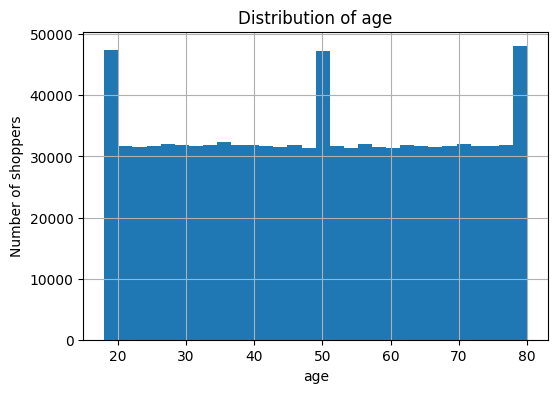

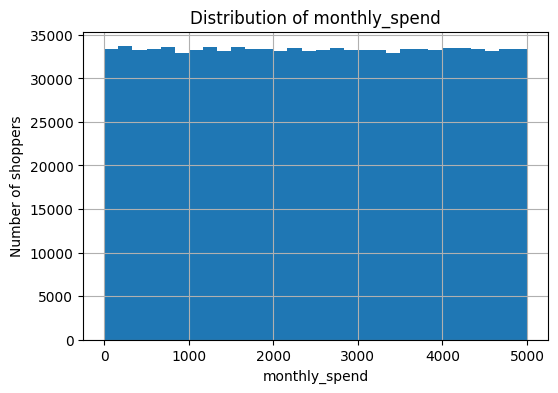

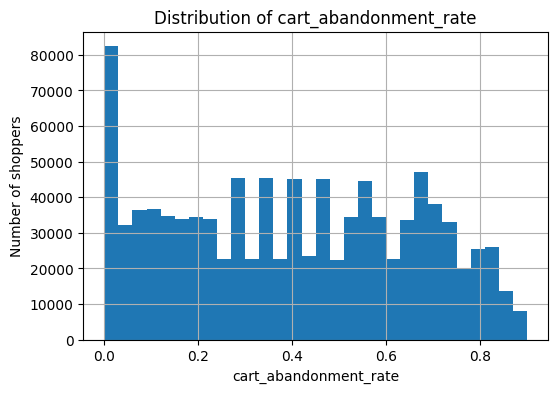

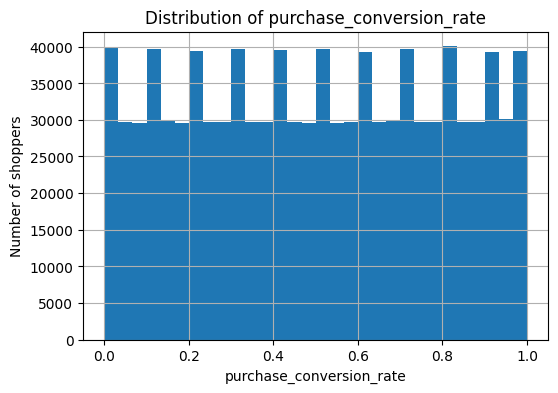

In [30]:
columns_to_plot = [
    "age",
    "monthly_spend",
    "cart_abandonment_rate",
    "purchase_conversion_rate"
]

for column in columns_to_plot:
    if column in clean_df.columns:
        clean_df[column].dropna().hist(bins=30, figsize=(6, 4))
        plt.title("Distribution of " + column)
        plt.xlabel(column)
        plt.ylabel("Number of shoppers")
        plt.show()

## Step 11 — Business Question 1: What shopping and abandonment indicators are available?

Summarize product views, average cart items, monthly checkout abandonments, abandonment rate and purchase conversion rate.

These are user-level measures, not steps in a timestamped conversion funnel.

In [31]:
question_1_columns = [
    "product_views_per_day",
    "cart_items_average",
    "checkout_abandonments_per_month",
    "cart_abandonment_rate",
    "purchase_conversion_rate"
]

available_columns = [
    column for column in question_1_columns if column in clean_df.columns
]

display(clean_df[available_columns].mean().to_frame("Average Value"))

,Average Value
product_views_per_day,25.018014
cart_items_average,5.494336
checkout_abandonments_per_month,4.997523
cart_abandonment_rate,0.402123
purchase_conversion_rate,0.500014


## Step 12 — Business Question 2: Which customer groups have higher abandonment?

Create age groups and compare average abandonment across age, income, financial stress and budgeting style.

In [32]:
# Create age groups
clean_df["age_group"] = pd.cut(
    clean_df["age"],
    bins=[0, 24, 34, 44, 54, 64, 120],
    labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
)

# Abandonment by age group
age_summary = clean_df.groupby("age_group", observed=False).agg(
    shoppers=("user_id", "nunique"),
    avg_abandonment=("cart_abandonment_rate", "mean")
).sort_values("avg_abandonment", ascending=False)

display(age_summary)

# Abandonment by income level
income_summary = clean_df.groupby("income_level").agg(
    shoppers=("user_id", "nunique"),
    avg_abandonment=("cart_abandonment_rate", "mean")
).sort_values("avg_abandonment", ascending=False)

display(income_summary)

# Abandonment by budgeting style
budget_summary = clean_df.groupby("budgeting_style").agg(
    shoppers=("user_id", "nunique"),
    avg_abandonment=("cart_abandonment_rate", "mean")
).sort_values("avg_abandonment", ascending=False)

display(budget_summary)

,shoppers,avg_abandonment
age_group,,
55-64,158371,0.402840
35-44,159344,0.402153
65+,254404,0.402063
25-34,159052,0.402048
45-54,158039,0.401919
18-24,110790,0.401587


,shoppers,avg_abandonment
income_level,,
14321,1,0.9
98317,1,0.9
164148,1,0.9
154177,1,0.9
179093,1,0.9
...,...,...
14390,1,0.0
181485,1,0.0
81977,1,0.0


,shoppers,avg_abandonment
budgeting_style,,
Loose,333438,0.402528
Moderate,333771,0.401997
Strict,332791,0.401843


## Step 13 — Business Question 3: Which preferred product categories have higher abandonment?

Compare the average shopper-level abandonment rate for each preferred category. This is a preference-based comparison, not proof of which product was left in a cart.

,shoppers,avg_abandonment,avg_order_value
product_category_preference,,,
Sports,125227,0.402981,255.398684
Toys,124735,0.402584,254.499042
Electronics,125074,0.402384,254.644762
Home & Kitchen,124609,0.402357,254.892793
Groceries,124988,0.402195,254.847513
Fashion,124904,0.402066,255.255700
Beauty,125409,0.401346,255.765958
Books,125054,0.401070,254.944392


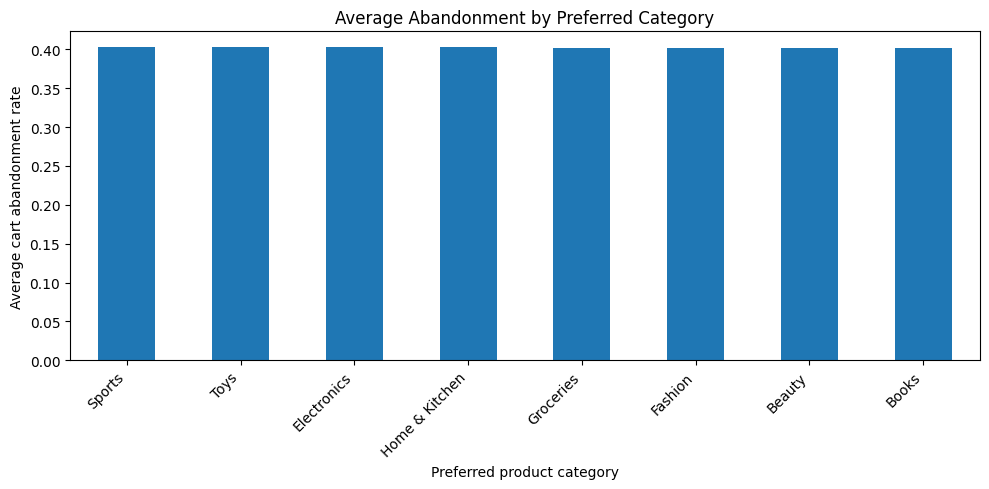

In [33]:
category_summary = clean_df.groupby("product_category_preference").agg(
    shoppers=("user_id", "nunique"),
    avg_abandonment=("cart_abandonment_rate", "mean"),
    avg_order_value=("average_order_value", "mean")
).sort_values("avg_abandonment", ascending=False)

display(category_summary)

category_summary["avg_abandonment"].plot(
    kind="bar", figsize=(10, 5), title="Average Abandonment by Preferred Category"
)
plt.ylabel("Average cart abandonment rate")
plt.xlabel("Preferred product category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Step 14 — Business Question 4: Do devices show different abandonment and conversion?

Compare shopper counts, average abandonment and average conversion by device type.

,shoppers,avg_abandonment,avg_conversion,avg_session_minutes
device_type,,,,
Mobile,600247,0.402332,0.500328,59.960804
Tablet,99908,0.402036,0.500299,60.039897
Desktop,299845,0.401733,0.499292,60.113242


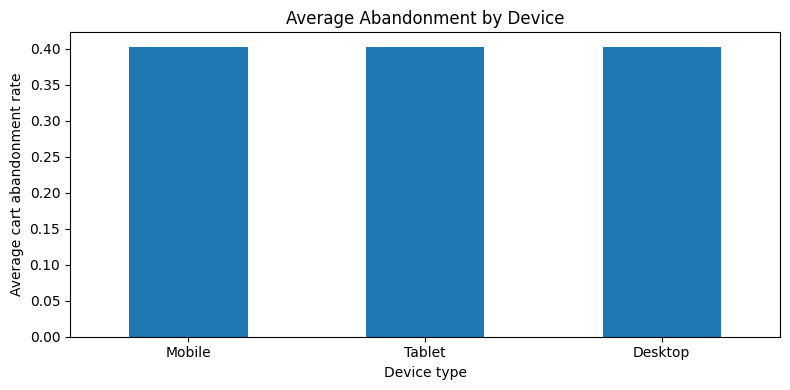

In [34]:
device_summary = clean_df.groupby("device_type").agg(
    shoppers=("user_id", "nunique"),
    avg_abandonment=("cart_abandonment_rate", "mean"),
    avg_conversion=("purchase_conversion_rate", "mean"),
    avg_session_minutes=("daily_session_time_minutes", "mean")
).sort_values("avg_abandonment", ascending=False)

display(device_summary)

device_summary["avg_abandonment"].plot(
    kind="bar", figsize=(8, 4), title="Average Abandonment by Device"
)
plt.ylabel("Average cart abandonment rate")
plt.xlabel("Device type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 15 — Business Question 5: What can we say about revenue impact?

The dataset includes monthly spend and average order value, but does not include the value of each abandoned cart. We therefore cannot calculate actual abandoned-cart revenue.

We can compare monthly spend and order value between groups with different abandonment levels, but label this as a comparison—not lost revenue.

In [35]:
clean_df["abandonment_group"] = pd.cut(
    clean_df["cart_abandonment_rate"],
    bins=[-0.001, 0.25, 0.50, 1.001],
    labels=["Low", "Medium", "High"]
)

revenue_comparison = clean_df.groupby("abandonment_group", observed=False).agg(
    shoppers=("user_id", "nunique"),
    avg_monthly_spend=("monthly_spend", "mean"),
    avg_order_value=("average_order_value", "mean"),
    avg_checkout_abandonments=("checkout_abandonments_per_month", "mean")
)

display(revenue_comparison)

,shoppers,avg_monthly_spend,avg_order_value,avg_checkout_abandonments
abandonment_group,,,,
Low,335729,2500.298872,255.506012,4.999786
Medium,283270,2499.640703,254.304095,4.999887
High,381001,2496.790276,255.154535,4.993772


## Step 16 — Business Question 6: What actions could the business investigate?

Use the device and category summaries to identify groups for further investigation. These are possible actions to test, not proven causes.

In [36]:
print("Highest average abandonment by device:")
display(device_summary.head(1))

print("Highest average abandonment by preferred category:")
display(category_summary.head(1))

print("Possible actions to investigate:")
print("1. Review the mobile shopping and checkout experience.")
print("2. Review product information, pricing and delivery information for high-abandonment preferences.")
print("3. Test clearer pricing and suitable payment options.")
print("4. Run controlled experiments before claiming an improvement.")

Highest average abandonment by device:


,shoppers,avg_abandonment,avg_conversion,avg_session_minutes
device_type,,,,
Mobile,600247,0.402332,0.500328,59.960804


Highest average abandonment by preferred category:


,shoppers,avg_abandonment,avg_order_value
product_category_preference,,,
Sports,125227,0.402981,255.398684


Possible actions to investigate:
1. Review the mobile shopping and checkout experience.
2. Review product information, pricing and delivery information for high-abandonment preferences.
3. Test clearer pricing and suitable payment options.
4. Run controlled experiments before claiming an improvement.


## Step 17 — Simple correlation analysis

Check whether selected numerical measures move together. Correlation does not prove that one factor causes another.

,cart_abandonment_rate,purchase_conversion_rate,monthly_spend,average_order_value,impulse_buying_score,stress_from_financial_decisions,daily_session_time_minutes,product_views_per_day
cart_abandonment_rate,1.000000,0.000656,-0.001853,-0.000816,0.961469,0.940364,-0.000274,0.000981
purchase_conversion_rate,0.000656,1.000000,0.000252,-0.000128,0.000475,0.000269,-0.000892,-0.001331
monthly_spend,-0.001853,0.000252,1.000000,-0.000295,-0.001688,-0.001465,-0.001336,-0.000832
average_order_value,-0.000816,-0.000128,-0.000295,1.000000,-0.000658,-0.000462,0.000282,-0.000312
impulse_buying_score,0.961469,0.000475,-0.001688,-0.000658,1.000000,0.916233,0.000304,0.000902
stress_from_financial_decisions,0.940364,0.000269,-0.001465,-0.000462,0.916233,1.000000,0.000215,0.001125
daily_session_time_minutes,-0.000274,-0.000892,-0.001336,0.000282,0.000304,0.000215,1.000000,-0.002373
product_views_per_day,0.000981,-0.001331,-0.000832,-0.000312,0.000902,0.001125,-0.002373,1.000000


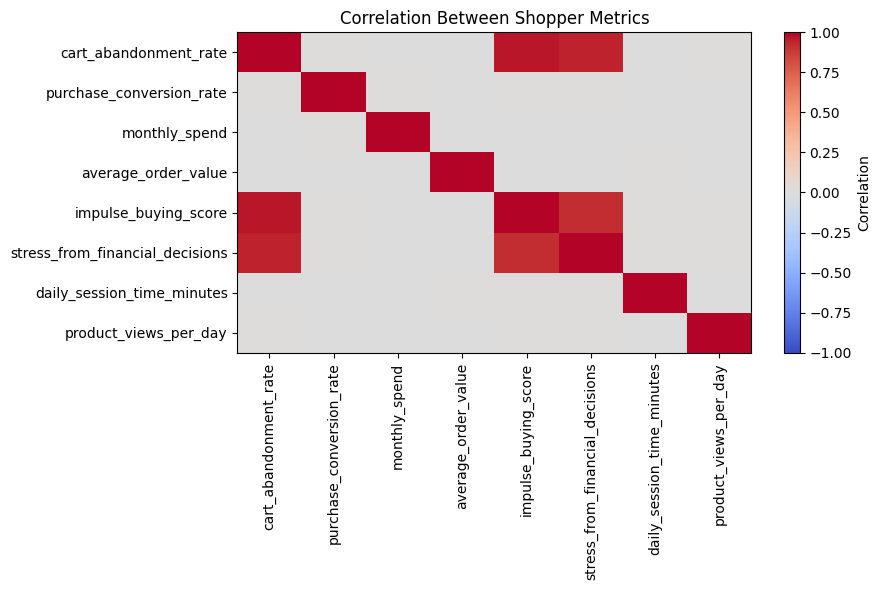

In [37]:
correlation_columns = [
    "cart_abandonment_rate",
    "purchase_conversion_rate",
    "monthly_spend",
    "average_order_value",
    "impulse_buying_score",
    "stress_from_financial_decisions",
    "daily_session_time_minutes",
    "product_views_per_day"
]

available_correlation_columns = [
    column for column in correlation_columns if column in clean_df.columns
]

correlation = clean_df[available_correlation_columns].corr()

display(correlation)

plt.figure(figsize=(9, 6))
plt.imshow(correlation, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.index)), correlation.index)
plt.title("Correlation Between Shopper Metrics")
plt.tight_layout()
plt.show()

## Step 18 — Save the cleaned dataset

Save the cleaned CSV and the main summary tables. In Kaggle, find these files in the notebook's Output section.

In [38]:
clean_df.to_csv(
    "/kaggle/working/e_commerce_shopper_behavior_cleaned.csv",
    index=False
)

device_summary.to_csv(
    "/kaggle/working/device_summary.csv"
)

category_summary.to_csv(
    "/kaggle/working/category_summary.csv"
)

age_summary.to_csv(
    "/kaggle/working/age_group_summary.csv"
)

print("Files saved successfully.")

Files saved successfully.


# Final business summary — complete after running the notebook

Use your actual results to fill these points:

1. The dataset contains __________ shopper profiles.
2. The age group with the highest average abandonment is __________.
3. The income group with the highest average abandonment is __________.
4. The preferred product category with the highest abandonment indicator is __________.
5. The device with the highest average abandonment is __________.
6. Exact abandoned-cart revenue cannot be measured using the supplied columns.
7. A business action worth testing is __________.

Do not fill the blanks with example values. Use your notebook results.

## Data limitations to mention in your portfolio
- The dataset is synthetic.
- One row represents a shopper profile, not a clickstream event.
- No exact page-by-page shopping funnel can be reconstructed.
- Preferred category does not identify an actual abandoned-cart item.
- Exact abandoned-cart monetary value is not available.